In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("datasets/winemag-data-130k-v2.csv")

print('Dataset Shape:', df.shape)

# Remove the index column
df = df.drop(columns=["Unnamed: 0"])

# Inspect duplicate reviews
print('\nNumber of Duplicate Reviews:', df.duplicated(subset=["title", "description"]).sum())

# Remove duplicate review pairs
df = df.drop_duplicates(subset=["title", "description"]).copy()

# Extract wine vintage
df["vintage"] = pd.to_numeric(
    df["title"].str.extract(r"\b((?:19|20)\d{2})\b")[0],
    errors="coerce"
)

# Inspect vintage coverage
print('\nVintage Summary Stats:')
print(df["vintage"].describe())
print('\nNumber of Missing Vintage Reviews:', df["vintage"].isna().sum())

Dataset Shape: (129971, 14)

Number of Duplicate Reviews: 9983

Vintage Summary Stats:
count    115703.000000
mean       2010.574168
std           3.847002
min        1904.000000
25%        2009.000000
50%        2011.000000
75%        2013.000000
max        2017.000000
Name: vintage, dtype: float64

Number of Missing Vintage Reviews: 4285


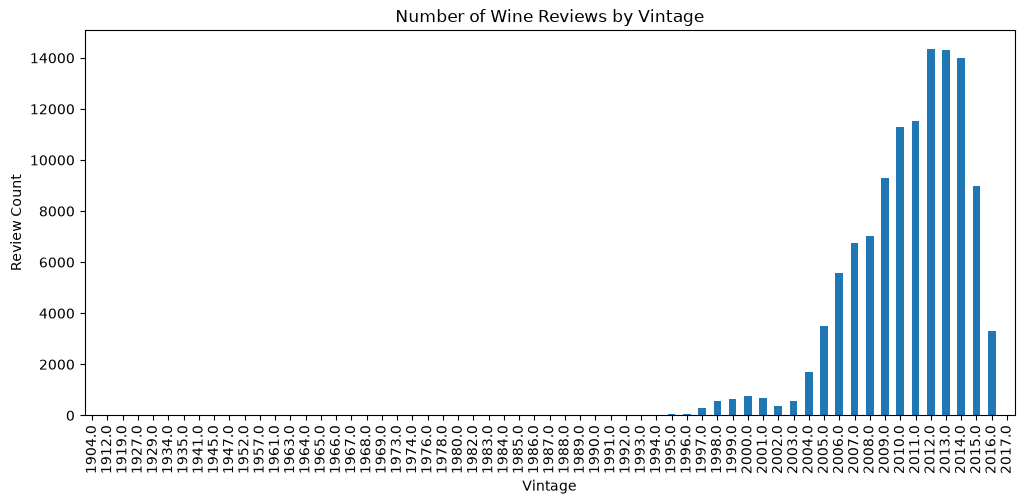

In [14]:
# Number of reviews by vintage (Like Dylan's Graph)
vintage_counts = df["vintage"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
vintage_counts.plot(kind="bar")
plt.title("Number of Wine Reviews by Vintage")
plt.xlabel("Vintage")
plt.ylabel("Review Count")
plt.show()

Looking at the distribution of Reviews, we can see that the largest chunk of our data comes from the ranges of 2004-2017 and we could use the data within this time frame for our project.

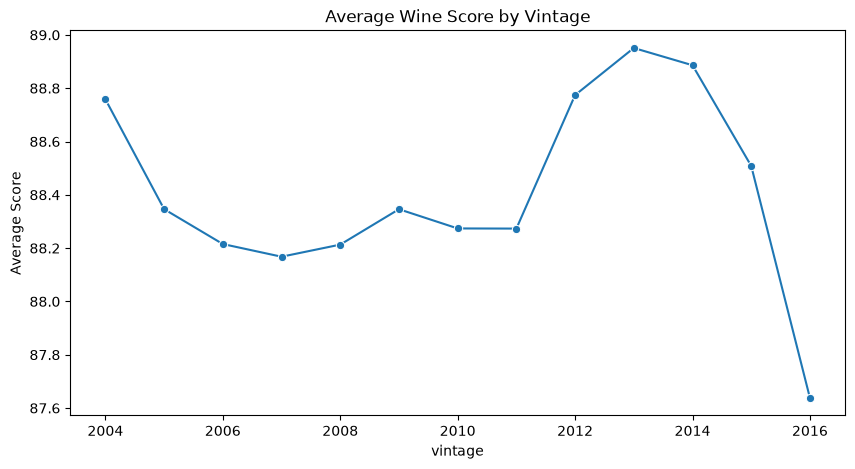

In [17]:
# Average score by vintage
yearly = (
    df.groupby("vintage")
    .agg(
        n_reviews=("points", "size"),
        mean_score=("points", "mean"),
        median_score=("points", "median")
    )
    .reset_index()
)

# Focus on well-represented vintages #reviews >= 100
yearly = yearly[yearly["n_reviews"] >= 1000]

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=yearly,
    x="vintage",
    y="mean_score",
    marker="o"
)
plt.title("Average Wine Score by Vintage")
plt.ylabel("Average Score")
plt.show()

Looking at this graph we see a decline in average scores of wines from 2004-2007. We also can see a very distinct increase in score from the years 2011 to 2013 then a sharp decline in 2016. We can investigate this further.

In [24]:
df["high_rated"] = (df["points"] >= 90).astype(int)

vintage_summary = (
    df.groupby("vintage")
    .agg(
        n_reviews=("points", "size"),
        mean_score=("points", "mean"),
        sd_score=("points", "std"),
        high_rated_pct=("high_rated", "mean")
    )
    .reset_index()
)

vintage_summary["high_rated_pct"] *= 100

display(
    vintage_summary[
        vintage_summary["vintage"].between(1997, 2017)
    ]
)

,vintage,n_reviews,mean_score,sd_score,high_rated_pct
40,1997.0,302,89.142384,3.574958,53.642384
41,1998.0,550,87.503636,3.461338,28.909091
42,1999.0,639,87.608764,3.479044,30.203443
43,2000.0,752,87.390957,3.198505,27.393617
44,2001.0,684,87.385965,3.267952,29.532164
45,2002.0,358,87.807263,3.448582,29.329609
46,2003.0,574,88.440767,2.947323,38.675958
47,2004.0,1714,88.758460,3.306312,44.632439
48,2005.0,3485,88.346341,3.314416,38.852224
49,2006.0,5566,88.215415,3.258570,35.555156


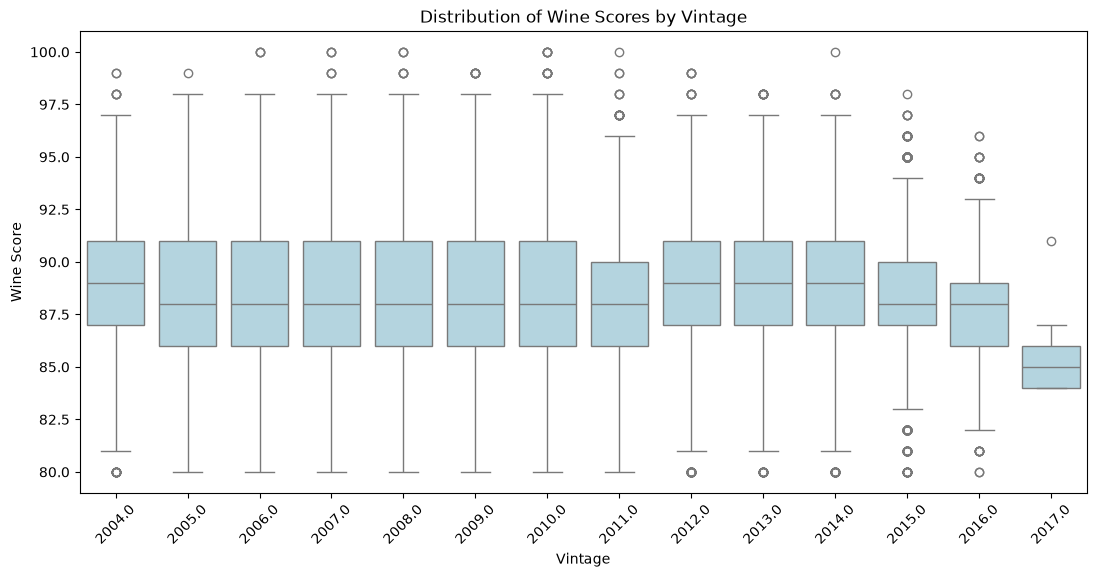

In [27]:
# Focus on vintages with substantial observations
subset = df[df["vintage"].between(2004, 2017)]

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=subset,
    x="vintage",
    y="points",
    color="lightblue"
)

plt.title("Distribution of Wine Scores by Vintage")
plt.xlabel("Vintage")
plt.ylabel("Wine Score")
plt.xticks(rotation=45)
plt.show()

From the table and graph aboe we can see that the average wine scores are fairly similar within eacch of the most observed years 2004-2017 but there is a very big difference in 2017. This can be attributed to the smaple size of 2017 being very small comapred to the other years.

In [29]:
# Count reviews per vintage
vintage_counts = df["vintage"].value_counts()

# Retain vintages with at least 100 reviews
valid_vintages = vintage_counts[
    vintage_counts >= 100
].index

df_eda = df[
    df["vintage"].isin(valid_vintages)
].copy()

print("Original observations:", len(df))
print("Filtered observations:", len(df_eda))
print("Remaining vintages:", sorted(df_eda["vintage"].unique()))

Original observations: 119988
Filtered observations: 115455
Remaining vintages: [np.float64(1997.0), np.float64(1998.0), np.float64(1999.0), np.float64(2000.0), np.float64(2001.0), np.float64(2002.0), np.float64(2003.0), np.float64(2004.0), np.float64(2005.0), np.float64(2006.0), np.float64(2007.0), np.float64(2008.0), np.float64(2009.0), np.float64(2010.0), np.float64(2011.0), np.float64(2012.0), np.float64(2013.0), np.float64(2014.0), np.float64(2015.0), np.float64(2016.0)]


If we removed 2017, wew only lose about 4k observations so we can talk about if that is worthwhile to do since we want to predict future years and we lose another year in our analysis of year to year model reliability/analysis.

In [31]:
comparison = (
    df[df["vintage"].isin([2012,2013,2014, 2015, 2016])]
    .groupby("vintage")
    .agg(
        n=("points", "size"),
        mean=("points", "mean"),
        median=("points", "median"),
        std=("points", "std"),
        high_rated_pct=("points", lambda x: (x >= 90).mean() * 100)
    )
)

display(comparison.round(2))

,n,mean,median,std,high_rated_pct
vintage,,,,,
2012.0,14360,88.77,89.0,3.01,42.86
2013.0,14326,88.95,89.0,2.94,44.76
2014.0,13998,88.89,89.0,2.94,42.83
2015.0,8969,88.51,88.0,2.79,37.28
2016.0,3310,87.64,88.0,2.42,23.99


Going back to 2016 being very different as well, we can see now that comapred ot the other previous years, 2016 is not too different with a similar median, but differs in the rate of highly rates wines (Over a score of 90).

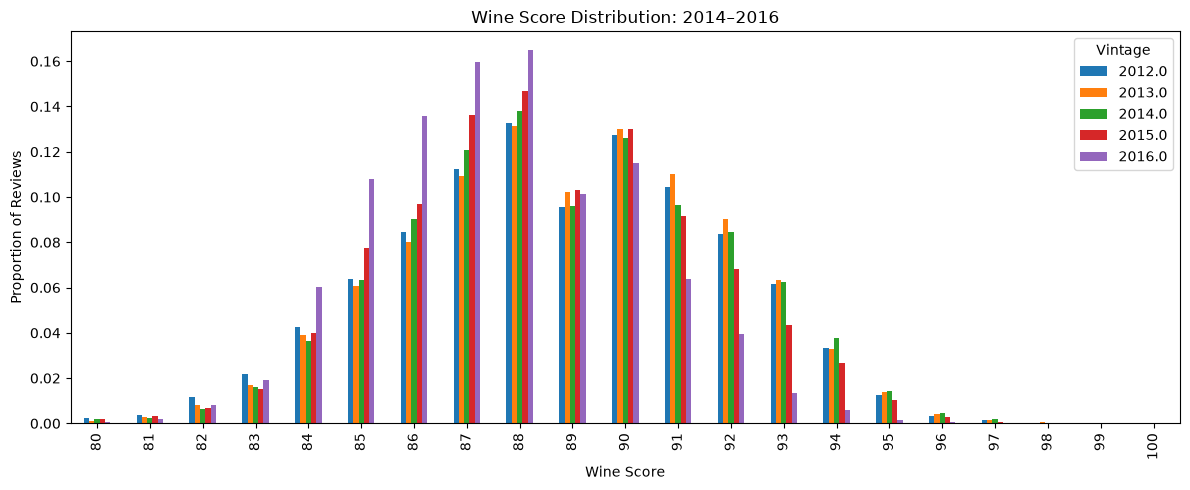

In [32]:
# Compare score distributions for 2014, 2015, and 2016
score_dist = pd.crosstab(
    df[df["vintage"].isin([2012, 2013, 2014, 2015, 2016])]["points"],
    df[df["vintage"].isin([2012, 2013, 2014, 2015, 2016])]["vintage"],
    normalize="columns"
)

score_dist.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Wine Score Distribution: 2014–2016")
plt.xlabel("Wine Score")
plt.ylabel("Proportion of Reviews")
plt.legend(title="Vintage")
plt.tight_layout()
plt.show()

Observation A: Scores shift toward the lower end in 2016
Looking at the purple bars (2016):
- Scores of 85 and 86 are noticeably more common than in earlier vintages.
- A score of 88 is the most common for 2016, representing approximately 16.5% of reviews.
- Scores of 91–94 are substantially less common in 2016.
- Scores of 95+ are extremely rare.
This suggests that the decline in the percentage of high-rated wines isn't just a random fluctuation around the 90-point threshold. There is a broader shift in the distribution toward lower scores.

Observation B: The 2012–2014 distributions are fairly similar
Looking at the blue, orange, and green bars:
- Scores of 88–91 are relatively common.
- Scores of 90–93 make up a substantial proportion of reviews.
- The overall shapes of the distributions are fairly consistent.
This suggests a degree of stability across these three vintages.

Observation C: 2015 appears to be a transition
The 2015 distribution (red) appears to fall between the earlier vintages and 2016.

For example, 2015 has more reviews scoring 85–88 than 2012–2014, while still having a greater proportion of scores above 90 than 2016.

This could indicate a gradual shift rather than a sudden change occurring only in 2016.

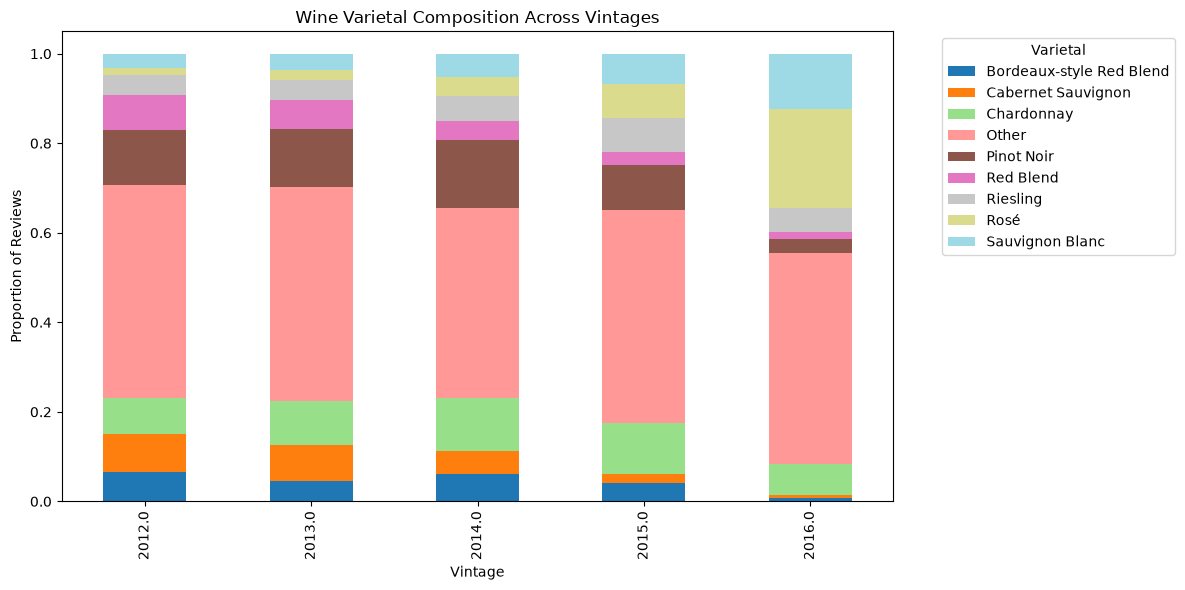

In [33]:
# Focus on 2012–2016
subset = df[df["vintage"].between(2012, 2016)].copy()

# Identify the 8 most common varietals
top_varieties = subset["variety"].value_counts().head(8).index

# Group all remaining varietals into Other
subset["variety_group"] = subset["variety"].where(
    subset["variety"].isin(top_varieties),
    "Other"
)

# Calculate proportions by vintage
variety_dist = pd.crosstab(
    subset["vintage"],
    subset["variety_group"],
    normalize="index"
)

# Plot
variety_dist.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="tab20"
)

plt.title("Wine Varietal Composition Across Vintages")
plt.xlabel("Vintage")
plt.ylabel("Proportion of Reviews")
plt.legend(
    title="Varietal",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

More Rose in 2016 than other years and not much Bordeaux-Style Red Blends

In [34]:
# Focus on the relevant years
subset = df[df["vintage"].between(2012, 2016)].copy()

# Select varietals of interest
varieties = [
    "Rosé",
    "Sauvignon Blanc",
    "Pinot Noir",
    "Cabernet Sauvignon",
    "Chardonnay"
]

subset = subset[subset["variety"].isin(varieties)]

# Summarize scores
variety_scores = (
    subset.groupby(["vintage", "variety"])
    .agg(
        n=("points", "size"),
        mean_score=("points", "mean"),
        high_rated_pct=("points", lambda x: (x >= 90).mean() * 100)
    )
    .reset_index()
)

display(variety_scores.round(2))

,vintage,variety,n,mean_score,high_rated_pct
0,2012.0,Cabernet Sauvignon,1209,89.04,50.04
1,2012.0,Chardonnay,1146,88.24,38.66
2,2012.0,Pinot Noir,1747,89.66,55.98
3,2012.0,Rosé,224,86.49,15.62
4,2012.0,Sauvignon Blanc,468,86.97,19.23
5,2013.0,Cabernet Sauvignon,1142,89.45,55.34
6,2013.0,Chardonnay,1426,88.99,47.48
7,2013.0,Pinot Noir,1855,90.13,63.94
8,2013.0,Rosé,303,86.88,18.48
9,2013.0,Sauvignon Blanc,537,87.66,28.49


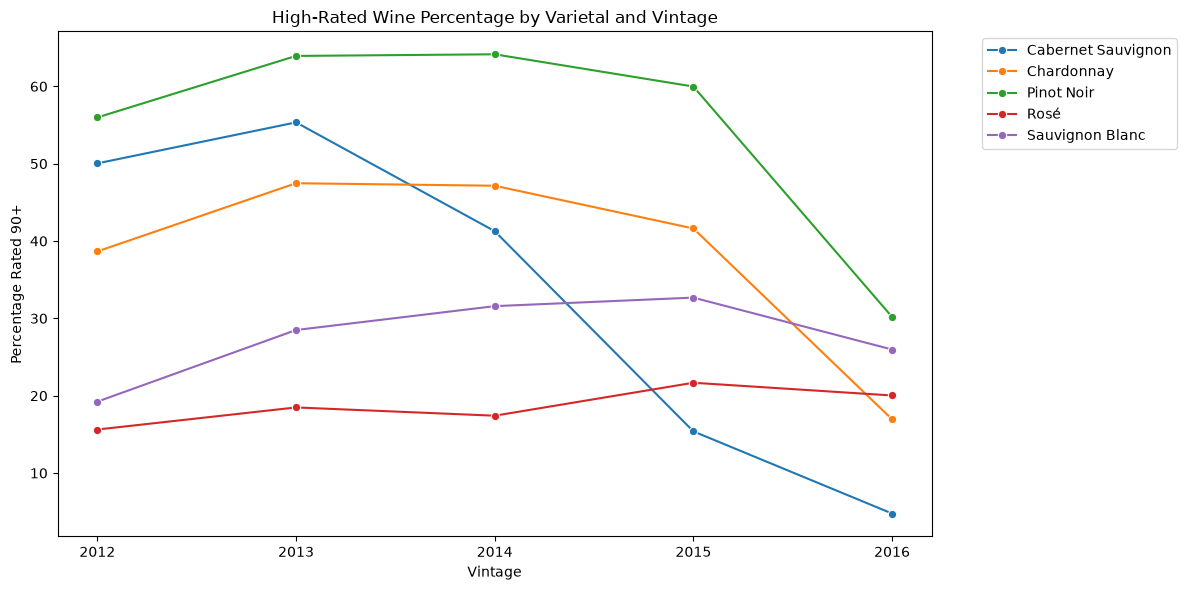

In [35]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=variety_scores,
    x="vintage",
    y="high_rated_pct",
    hue="variety",
    marker="o"
)

plt.title("High-Rated Wine Percentage by Varietal and Vintage")
plt.xlabel("Vintage")
plt.ylabel("Percentage Rated 90+")
plt.xticks([2012, 2013, 2014, 2015, 2016])
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()